# Просмотр повреждений автомобилей

Случайные фотографии из **Coco Car Damage Detection Dataset** с существующей разметкой повреждений: красная заливка показывает область повреждения, пунктирная рамка — её границы.

Запустите ячейки сверху вниз. Для новой случайной подборки достаточно повторно выполнить **последнюю ячейку**. Настройки: `SPLIT` (`train`, `val`, `all`), `N_IMAGES`, `N_COLS` и `SEED`. При `SEED = None` подборка случайна; целое число фиксирует выборку.

Используются файлы `COCO_train_annos.json` и `COCO_val_annos.json` с классом `damage`. Для `test` разметка повреждений в этом датасете отсутствует.

In [1]:
import json
import math
import random
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, Rectangle
from PIL import Image


In [2]:
# Ноутбук можно запускать как из корня проекта, так и из папки code.
working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [working_dir, *working_dir.parents]
     if (path / "datasets" / "Coco Car Damage Detection Dataset").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден datasets/Coco Car Damage Detection Dataset. "
        "Откройте ноутбук из папки проекта или укажите DATASET_ROOT вручную."
    )

DATASET_ROOT = PROJECT_ROOT / "datasets" / "Coco Car Damage Detection Dataset"

SPLIT = "train"          # "train", "val" или "all"
N_IMAGES = 6
N_COLS = 3
SEED = None             # Например, 42 — для воспроизводимой выборки
SHOW_MASKS = True        # Полупрозрачные полигоны повреждений
SHOW_BOXES = True        # Прямоугольные рамки повреждений
SHOW_LABELS = True       # Название класса и category_id рядом с областью
ONLY_ANNOTATED = True    # Выбирать только фото с разметкой


In [3]:
def load_damage_dataset(dataset_root, split="train"):
    """Загрузить COCO-разметку; ID изображений учитываются отдельно в каждом split."""
    if split not in {"train", "val", "all"}:
        raise ValueError('split должен быть "train", "val" или "all".')

    samples = []
    splits = ("train", "val") if split == "all" else (split,)
    for split_name in splits:
        annotation_path = dataset_root / split_name / f"COCO_{split_name}_annos.json"
        with annotation_path.open(encoding="utf-8") as stream:
            coco = json.load(stream)

        categories = {item["id"]: item["name"] for item in coco["categories"]}
        damage_ids = {
            category_id for category_id, name in categories.items()
            if name.lower() == "damage"
        }
        if not damage_ids:
            raise ValueError(f"В {annotation_path.name} нет класса damage.")

        by_image = defaultdict(list)
        for annotation in coco["annotations"]:
            if annotation["category_id"] in damage_ids:
                by_image[annotation["image_id"]].append(annotation)

        for image_info in coco["images"]:
            image_path = dataset_root / split_name / image_info["file_name"]
            if not image_path.is_file():
                image_path = dataset_root / "img" / image_info["file_name"]
            if not image_path.is_file():
                raise FileNotFoundError(f"Не найдено изображение: {image_info['file_name']}")

            samples.append({
                "split": split_name,
                "image_info": image_info,
                "image_path": image_path,
                "annotations": by_image[image_info["id"]],
                "categories": categories,
            })
    return samples


# Загружаем обе выборки один раз, чтобы менять SPLIT в последней ячейке.
dataset = load_damage_dataset(DATASET_ROOT, split="all")
for split_name in ("train", "val"):
    split_samples = [sample for sample in dataset if sample["split"] == split_name]
    n_annotations = sum(len(sample["annotations"]) for sample in split_samples)
    print(f"{split_name}: {len(split_samples)} фото, {n_annotations} повреждений")


train: 59 фото, 140 повреждений
val: 11 фото, 24 повреждений


In [4]:
def show_random_damage_images(
    samples, split="train", n_images=6, n_cols=3, seed=None,
    show_masks=True, show_boxes=True, show_labels=True, only_annotated=True,
):
    """Показать неповторяющуюся случайную выборку и вернуть figure и её записи."""
    if split not in {"train", "val", "all"}:
        raise ValueError('split должен быть "train", "val" или "all".')
    if n_images < 1 or n_cols < 1:
        raise ValueError("n_images и n_cols должны быть положительными.")

    candidates = [
        sample for sample in samples
        if (split == "all" or sample["split"] == split)
        and (not only_annotated or sample["annotations"])
    ]
    if not candidates:
        raise ValueError("Нет фотографий для выбранных настроек.")

    selected = random.Random(seed).sample(candidates, min(n_images, len(candidates)))
    cols = min(n_cols, len(selected))
    rows = math.ceil(len(selected) / cols)
    fig, axes = plt.subplots(
        rows, cols, figsize=(5 * cols, 4.8 * rows), squeeze=False,
    )
    color = "#ed303b"

    for ax, sample in zip(axes.flat, selected):
        with Image.open(sample["image_path"]) as source:
            image = source.convert("RGB")
        width, height = image.size
        info = sample["image_info"]
        # COCO: координаты относятся к ширине/высоте из файла аннотаций.
        scale_x = width / info.get("width", width)
        scale_y = height / info.get("height", height)
        ax.imshow(image, extent=(0, width, height, 0))

        for index, annotation in enumerate(sample["annotations"], start=1):
            if show_masks:
                segmentation = annotation.get("segmentation", [])
                if not isinstance(segmentation, list):
                    raise ValueError("Этот просмотрщик ожидает COCO-полигоны в segmentation.")
                for polygon in segmentation:
                    if len(polygon) < 6 or len(polygon) % 2:
                        continue
                    points = np.asarray(polygon, dtype=float).reshape(-1, 2)
                    points *= [scale_x, scale_y]
                    ax.add_patch(Polygon(
                        points, closed=True,
                        facecolor=to_rgba(color, 0.24), edgecolor=color, linewidth=1.6,
                    ))

            bbox = annotation.get("bbox")
            if bbox and (show_boxes or show_labels):
                # COCO bbox = [x, y, width, height], а не [x1, y1, x2, y2].
                x, y, box_width, box_height = bbox
                x, y = x * scale_x, y * scale_y
                box_width, box_height = box_width * scale_x, box_height * scale_y
                if show_boxes:
                    ax.add_patch(Rectangle(
                        (x, y), box_width, box_height,
                        fill=False, edgecolor=color, linewidth=1.5, linestyle="--",
                    ))
                if show_labels:
                    category_id = annotation["category_id"]
                    category_name = sample["categories"][category_id]
                    ax.text(
                        x, y, f"{category_name} (id={category_id})",
                        color="white", fontsize=8,
                        va="top", bbox={"facecolor": color, "edgecolor": "none", "alpha": 0.9},
                    )

        ax.set_title(
            f"{sample['split']} / {info['file_name']}\n"
            f"Повреждений: {len(sample['annotations'])}",
            fontsize=11,
        )
        ax.set_xlim(0, width)
        ax.set_ylim(height, 0)
        ax.axis("off")

    for ax in list(axes.flat)[len(selected):]:
        ax.axis("off")

    legend = []
    if show_masks:
        legend.append(Line2D([0], [0], color=color, lw=3, label="Область повреждения"))
    if show_boxes:
        legend.append(Line2D([0], [0], color=color, lw=1.5, ls="--", label="Рамка повреждения"))
    if legend:
        fig.legend(handles=legend, loc="lower center", ncol=len(legend), frameon=False)
    fig.tight_layout(rect=(0, 0.04 if legend else 0, 1, 1))
    plt.show()
    return fig, selected


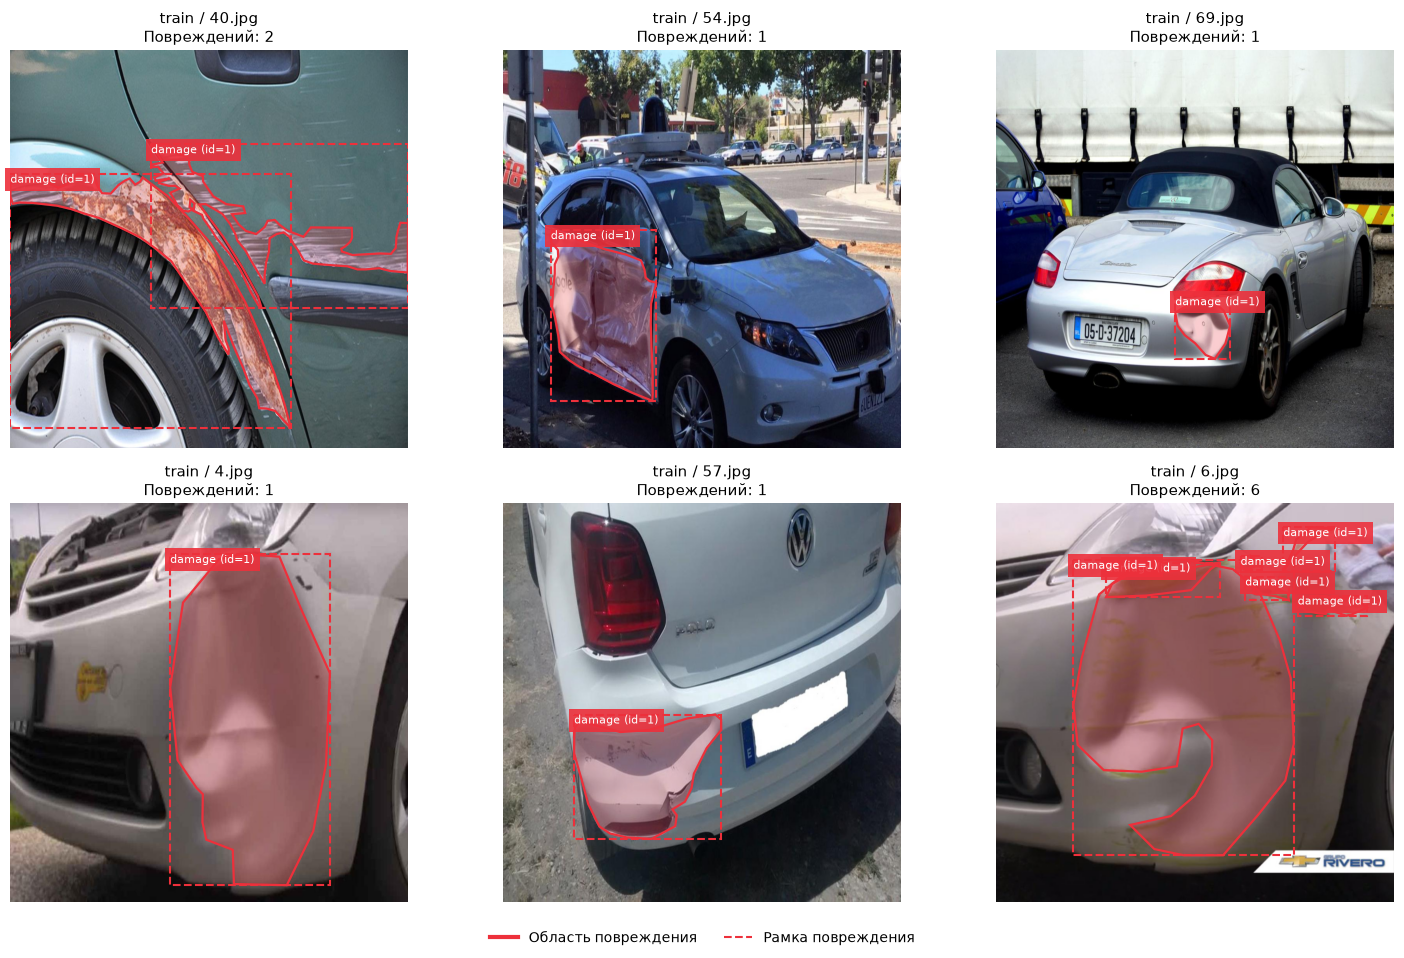

In [5]:
# Повторно запустите эту ячейку для новой случайной подборки.
figure, selected_images = show_random_damage_images(
    dataset,
    split=SPLIT,
    n_images=N_IMAGES,
    n_cols=N_COLS,
    seed=SEED,
    show_masks=SHOW_MASKS,
    show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS,
    only_annotated=ONLY_ANNOTATED,
)
